In [19]:
# %pip install pandas numpy matplotlib boto3 pyarrow python-dotenv lightgbm scikit-learn

In [ ]:
import hashlib
import json
import os
import platform
from importlib.metadata import version
from io import BytesIO
from pathlib import Path

import boto3
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from dotenv import load_dotenv
from IPython.display import display
from lightgbm import LGBMRegressor

repo_root = Path.cwd().resolve()
if not (repo_root / "docker-compose.yml").exists():
    repo_root = repo_root.parent

assert (repo_root / "docker-compose.yml").exists(), "Hãy mở notebook trong repo hoặc models"
assert (repo_root / ".env").exists(), "Cần tạo .env theo .env.example của nhóm"
load_dotenv(repo_root / ".env")

TIMEZONE = "Asia/Shanghai"
plt.rcParams["figure.dpi"] = 110

print("Python:", platform.python_version())
for package in ["pandas", "numpy", "lightgbm", "scikit-learn", "boto3", "pyarrow"]:
    print(f"{package}: {version(package)}")

Python: 3.11.18
pandas: 2.3.3
numpy: 2.4.6
lightgbm: 4.7.0
scikit-learn: 1.9.1
boto3: 1.40.70
pyarrow: 22.0.0


## 2. Đọc dữ liệu từ MinIO



In [21]:
s3 = boto3.client(
    "s3",
    endpoint_url=os.getenv("MINIO_ENDPOINT", "http://localhost:9000"),
    aws_access_key_id=os.getenv("MINIO_ROOT_USER") or os.getenv("AWS_ACCESS_KEY_ID"),
    aws_secret_access_key=(os.getenv("MINIO_ROOT_PASSWORD") or os.getenv("AWS_SECRET_ACCESS_KEY")),
    region_name=os.getenv("AWS_DEFAULT_REGION", "us-east-1"),
)

bucket = "raw"
prefix = "beijing_pm25"

response = s3.get_object(Bucket=bucket, Key=f"{prefix}/manifest.json")
with response["Body"] as body:
    manifest = json.loads(body.read())

assert manifest["source_timezone"] == TIMEZONE, "Timezone nguồn khác giả định của notebook"

frames = []
for path, expected_checksum in sorted(manifest["sha256_checksum"].items()):
    response = s3.get_object(Bucket=bucket, Key=f"{prefix}/{path}")
    with response["Body"] as body:
        content = body.read()

    actual_checksum = hashlib.sha256(content).hexdigest()
    assert actual_checksum == expected_checksum, f"Sai checksum: {path}"
    frames.append(pd.read_parquet(BytesIO(content)))

assert len(frames) == 60, "Cần toàn bộ 60 file Parquet, không dùng mẫu một tuần"
df = pd.concat(frames, ignore_index=True)
del frames

df["station_id"] = df["station_id"].astype("string")
df["event_time"] = pd.to_datetime(df["event_time"], utc=True)
df = df.sort_values(["station_id", "event_time"]).reset_index(drop=True)

assert len(df) == manifest["row_count"] == 420768
assert df["station_id"].nunique() == manifest["station_count"] == 12
print("Số file:", len(manifest["sha256_checksum"]))
print("Số dòng:", len(df))
print("Số trạm:", df["station_id"].nunique())
print("Nguồn:", manifest["source_url"])
display(df.head())

Số file: 60
Số dòng: 420768
Số trạm: 12
Nguồn: https://www.kaggle.com/datasets/sid321axn/beijing-multisite-airquality-data-set


,station_id,event_time,pm25_ug_m3,temperature_c,relative_humidity_pct,wind_speed_m_s,wind_direction_deg
0,beijing_Aotizhongxin,2013-02-28 16:00:00+00:00,4.0,-0.7,24.008842,4.4,337.5
1,beijing_Aotizhongxin,2013-02-28 17:00:00+00:00,8.0,-1.1,26.013678,4.7,0.0
2,beijing_Aotizhongxin,2013-02-28 18:00:00+00:00,7.0,-1.1,26.013678,5.6,337.5
3,beijing_Aotizhongxin,2013-02-28 19:00:00+00:00,6.0,-1.4,24.007753,3.1,315.0
4,beijing_Aotizhongxin,2013-02-28 20:00:00+00:00,3.0,-2.0,24.876783,2.0,0.0


## 3. Kiểm tra chất lượng dữ liệu


In [22]:
assert df["station_id"].notna().all()
assert df["event_time"].notna().all()
assert not df.duplicated(["station_id", "event_time"]).any()

hour_gap = df.groupby("station_id")["event_time"].diff()
unexpected_gap = hour_gap.notna() & hour_gap.ne(pd.Timedelta(hours=1))
print("Số khoảng cách khác 1 giờ:", unexpected_gap.sum())
assert not unexpected_gap.any(), "Cần bổ sung lưới giờ từng trạm trước khi tạo lag"

station_summary = df.groupby("station_id").agg(
    so_dong=("event_time", "size"),
    bat_dau_utc=("event_time", "min"),
    ket_thuc_utc=("event_time", "max"),
    thieu_pm25=("pm25_ug_m3", lambda x: x.isna().sum()),
)
display(station_summary)
display(df.isna().sum().rename("so_o_thieu").to_frame())

Số khoảng cách khác 1 giờ: 0


,so_dong,bat_dau_utc,ket_thuc_utc,thieu_pm25
station_id,,,,
beijing_Aotizhongxin,35064,2013-02-28 16:00:00+00:00,2017-02-28 15:00:00+00:00,925
beijing_Changping,35064,2013-02-28 16:00:00+00:00,2017-02-28 15:00:00+00:00,774
beijing_Dingling,35064,2013-02-28 16:00:00+00:00,2017-02-28 15:00:00+00:00,779
beijing_Dongsi,35064,2013-02-28 16:00:00+00:00,2017-02-28 15:00:00+00:00,750
beijing_Guanyuan,35064,2013-02-28 16:00:00+00:00,2017-02-28 15:00:00+00:00,616
beijing_Gucheng,35064,2013-02-28 16:00:00+00:00,2017-02-28 15:00:00+00:00,646
beijing_Huairou,35064,2013-02-28 16:00:00+00:00,2017-02-28 15:00:00+00:00,953
beijing_Nongzhanguan,35064,2013-02-28 16:00:00+00:00,2017-02-28 15:00:00+00:00,628
beijing_Shunyi,35064,2013-02-28 16:00:00+00:00,2017-02-28 15:00:00+00:00,913


,so_o_thieu
station_id,0
event_time,0
pm25_ug_m3,8739
temperature_c,398
relative_humidity_pct,403
wind_speed_m_s,318
wind_direction_deg,1822


In [23]:
numeric_cols = [
    "pm25_ug_m3",
    "temperature_c",
    "relative_humidity_pct",
    "wind_speed_m_s",
    "wind_direction_deg",
]

invalid = pd.DataFrame(
    {
        "pm25_am": df["pm25_ug_m3"] < 0,
        "do_am_ngoai_0_100": (
            (df["relative_humidity_pct"] < 0) | (df["relative_humidity_pct"] > 100)
        ),
        "toc_do_gio_am": df["wind_speed_m_s"] < 0,
        "huong_gio_ngoai_0_360": (
            (df["wind_direction_deg"] < 0) | (df["wind_direction_deg"] >= 360)
        ),
    }
)
display(invalid.sum().rename("so_dong_khong_hop_le").to_frame())
assert not invalid.any().any(), "Có giá trị vi phạm; cần kiểm tra nguồn trước khi chạy tiếp"
assert not np.isinf(df[numeric_cols].to_numpy(dtype=float)).any()
display(df[numeric_cols].describe(percentiles=[0.01, 0.5, 0.95, 0.99]).T.round(2))

,so_dong_khong_hop_le
pm25_am,0
do_am_ngoai_0_100,0
toc_do_gio_am,0
huong_gio_ngoai_0_360,0


,count,mean,std,min,1%,50%,95%,99%,max
pm25_ug_m3,412029.0,79.79,80.82,2.00,3.00,55.00,242.00,370.00,999.0
temperature_c,420370.0,13.54,11.44,-19.90,-7.90,14.50,30.60,33.80,41.6
relative_humidity_pct,420365.0,53.25,25.36,1.69,10.02,52.12,93.95,98.77,100.0
wind_speed_m_s,420450.0,1.73,1.25,0.00,0.00,1.40,4.30,6.10,13.2
wind_direction_deg,418946.0,157.46,108.64,0.00,0.00,135.00,337.50,337.50,337.5


In [24]:
peak_index = df["pm25_ug_m3"].idxmax()
peak_time = df.loc[peak_index, "event_time"]
peak_station = df.loc[peak_index, "station_id"]

around_peak = df["station_id"].eq(peak_station) & df["event_time"].between(
    peak_time - pd.Timedelta(hours=3), peak_time + pd.Timedelta(hours=3)
)
display(df.loc[around_peak, ["station_id", "event_time", "pm25_ug_m3"]])
display(
    df.loc[df["event_time"].eq(peak_time), ["station_id", "event_time", "pm25_ug_m3"]].sort_values(
        "pm25_ug_m3", ascending=False
    )
)

,station_id,event_time,pm25_ug_m3
411479,beijing_Wanshouxigong,2016-02-07 15:00:00+00:00,171.0
411480,beijing_Wanshouxigong,2016-02-07 16:00:00+00:00,238.0
411481,beijing_Wanshouxigong,2016-02-07 17:00:00+00:00,826.0
411482,beijing_Wanshouxigong,2016-02-07 18:00:00+00:00,999.0
411483,beijing_Wanshouxigong,2016-02-07 19:00:00+00:00,857.0
411484,beijing_Wanshouxigong,2016-02-07 20:00:00+00:00,748.0
411485,beijing_Wanshouxigong,2016-02-07 21:00:00+00:00,662.0


,station_id,event_time,pm25_ug_m3
411482,beijing_Wanshouxigong,2016-02-07 18:00:00+00:00,999.0
376418,beijing_Wanliu,2016-02-07 18:00:00+00:00,957.0
306290,beijing_Shunyi,2016-02-07 18:00:00+00:00,941.0
25778,beijing_Aotizhongxin,2016-02-07 18:00:00+00:00,898.0
60842,beijing_Changping,2016-02-07 18:00:00+00:00,882.0
130970,beijing_Dongsi,2016-02-07 18:00:00+00:00,642.0
95906,beijing_Dingling,2016-02-07 18:00:00+00:00,610.0
201098,beijing_Gucheng,2016-02-07 18:00:00+00:00,536.0
166034,beijing_Guanyuan,2016-02-07 18:00:00+00:00,534.0
341354,beijing_Tiantan,2016-02-07 18:00:00+00:00,508.0


## 4. Tạo nhãn và đặc trưng


In [25]:
data = df.copy()
grouped = data.groupby("station_id")["pm25_ug_m3"]

data["target"] = grouped.shift(-1)
data["target_time"] = data["event_time"] + pd.Timedelta(hours=1)

for lag in [1, 3, 24]:
    data[f"pm25_lag_{lag}h"] = grouped.shift(lag)

local_time = data["event_time"].dt.tz_convert(TIMEZONE)
data["hour"] = local_time.dt.hour
data["dayofweek"] = local_time.dt.dayofweek
data["month"] = local_time.dt.month

missing_current = data["pm25_ug_m3"].isna()
missing_target = data["target"].isna()
print("Tổng số dòng:", len(data))
print("Thiếu PM2.5 hiện tại:", missing_current.sum())
print("Có PM2.5 hiện tại nhưng thiếu nhãn:", ((~missing_current) & missing_target).sum())
print("Số dòng cần loại:", (missing_current | missing_target).sum())

# Chỉ loại sau khi đã tạo xong lag.
model_data = data.dropna(subset=["pm25_ug_m3", "target"]).copy()
print("Số dòng còn lại:", len(model_data))

Tổng số dòng: 420768
Thiếu PM2.5 hiện tại: 8739
Có PM2.5 hiện tại nhưng thiếu nhãn: 2849
Số dòng cần loại: 11588
Số dòng còn lại: 409180


## 5. Chia train/test theo thời gian của nhãn



In [26]:
train_start = pd.Timestamp("2013-01-01", tz=TIMEZONE)
train_end = pd.Timestamp("2016-01-01", tz=TIMEZONE)
test_start = pd.Timestamp("2016-03-01", tz=TIMEZONE)
test_end = pd.Timestamp("2017-03-01", tz=TIMEZONE)

target_local = model_data["target_time"].dt.tz_convert(TIMEZONE)
train = model_data.loc[(target_local >= train_start) & (target_local < train_end)].copy()
test = model_data.loc[(target_local >= test_start) & (target_local < test_end)].copy()

assert len(train) > 0 and len(test) > 0
assert train["target_time"].max() < test["target_time"].min()
print("Số mẫu train:", len(train))
print("Số mẫu test:", len(test))
for name, frame in [("Train", train), ("Test", test)]:
    times = frame["target_time"].dt.tz_convert(TIMEZONE)
    print(name, "— nhãn từ", times.min(), "đến", times.max())

test["target_month"] = test["target_time"].dt.tz_convert(TIMEZONE).dt.strftime("%Y-%m")
monthly_counts = pd.crosstab(test["target_month"], test["station_id"])
expected_months = pd.period_range("2016-03", "2017-02", freq="M").astype(str).tolist()
assert monthly_counts.index.tolist() == expected_months
assert monthly_counts.shape[1] == 12
assert (monthly_counts > 0).all().all()
display(monthly_counts)
print("Test đủ 12 tháng và mỗi tháng có mẫu của cả 12 trạm.")

Số mẫu train: 290312
Số mẫu test: 101836
Train — nhãn từ 2013-03-01 01:00:00+08:00 đến 2015-12-31 23:00:00+08:00
Test — nhãn từ 2016-03-01 00:00:00+08:00 đến 2017-02-28 23:00:00+08:00


station_id,beijing_Aotizhongxin,beijing_Changping,beijing_Dingling,beijing_Dongsi,beijing_Guanyuan,beijing_Gucheng,beijing_Huairou,beijing_Nongzhanguan,beijing_Shunyi,beijing_Tiantan,beijing_Wanliu,beijing_Wanshouxigong
target_month,,,,,,,,,,,,
2016-03,699,722,721,707,724,721,725,721,705,721,720,724
2016-04,675,699,688,673,698,692,683,694,642,677,700,685
2016-05,732,719,709,705,734,722,728,717,672,735,727,714
2016-06,697,702,717,658,711,708,714,717,699,705,706,641
2016-07,710,725,726,609,685,733,721,732,704,735,734,727
2016-08,732,728,728,736,738,739,729,742,725,728,738,735
2016-09,690,691,652,684,690,655,672,691,628,686,693,686
2016-10,735,734,610,695,728,736,737,737,695,733,733,737
2016-11,711,720,715,715,716,711,718,714,718,717,717,718


Test đủ 12 tháng và mỗi tháng có mẫu của cả 12 trạm.


Tỷ lệ mẫu test hợp lệ theo tháng và trạm (%):


station_id,beijing_Aotizhongxin,beijing_Changping,beijing_Dingling,beijing_Dongsi,beijing_Guanyuan,beijing_Gucheng,beijing_Huairou,beijing_Nongzhanguan,beijing_Shunyi,beijing_Tiantan,beijing_Wanliu,beijing_Wanshouxigong
target_month,,,,,,,,,,,,
2016-03,93.95,97.04,96.91,95.03,97.31,96.91,97.45,96.91,94.76,96.91,96.77,97.31
2016-04,93.75,97.08,95.56,93.47,96.94,96.11,94.86,96.39,89.17,94.03,97.22,95.14
2016-05,98.39,96.64,95.30,94.76,98.66,97.04,97.85,96.37,90.32,98.79,97.72,95.97
2016-06,96.81,97.50,99.58,91.39,98.75,98.33,99.17,99.58,97.08,97.92,98.06,89.03
2016-07,95.43,97.45,97.58,81.85,92.07,98.52,96.91,98.39,94.62,98.79,98.66,97.72
2016-08,98.39,97.85,97.85,98.92,99.19,99.33,97.98,99.73,97.45,97.85,99.19,98.79
2016-09,95.83,95.97,90.56,95.00,95.83,90.97,93.33,95.97,87.22,95.28,96.25,95.28
2016-10,98.79,98.66,81.99,93.41,97.85,98.92,99.06,99.06,93.41,98.52,98.52,99.06
2016-11,98.75,100.00,99.31,99.31,99.44,98.75,99.72,99.17,99.72,99.58,99.58,99.72


Đánh giá 101836/105120 mẫu (96.88%).


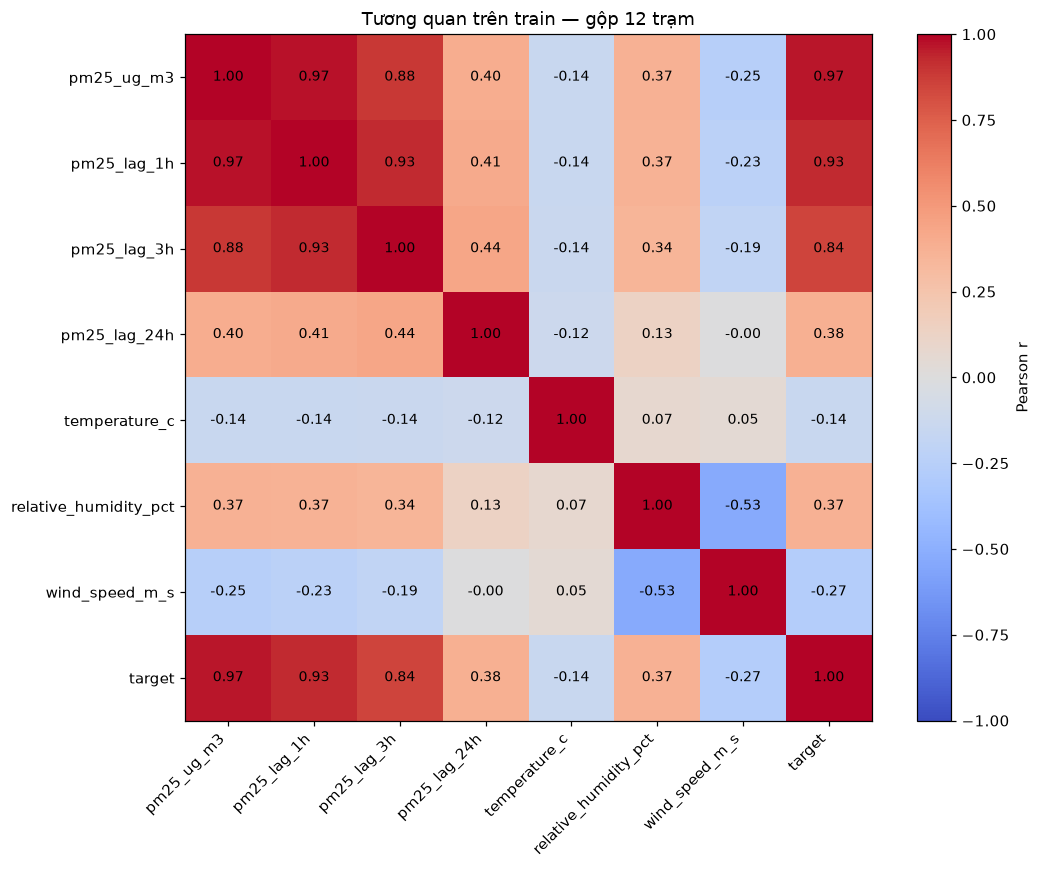

In [27]:
expected_hours = pd.Series(
    [pd.Period(month, freq="M").days_in_month * 24 for month in expected_months],
    index=expected_months,
)
coverage_pct = monthly_counts.div(expected_hours, axis=0) * 100
print("Tỷ lệ mẫu test hợp lệ theo tháng và trạm (%):")
display(coverage_pct.round(2))
expected_total = int(expected_hours.sum() * monthly_counts.shape[1])
print(f"Đánh giá {len(test)}/{expected_total} mẫu ({100 * len(test) / expected_total:.2f}%).")

corr_cols = [
    "pm25_ug_m3",
    "pm25_lag_1h",
    "pm25_lag_3h",
    "pm25_lag_24h",
    "temperature_c",
    "relative_humidity_pct",
    "wind_speed_m_s",
    "target",
]
corr = train[corr_cols].corr()
fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=9)
fig.colorbar(im, ax=ax, label="Pearson r")
ax.set_title("Tương quan trên train — gộp 12 trạm")
plt.tight_layout()
plt.show()

## 6. Persistence 



In [28]:
predictions = test[["station_id", "target_time", "target_month", "target"]].copy()
predictions = predictions.rename(columns={"target": "actual"})
predictions["Persistence"] = test["pm25_ug_m3"]
display(predictions.head())

,station_id,target_time,target_month,actual,Persistence
26303,beijing_Aotizhongxin,2016-02-29 16:00:00+00:00,2016-03,63.0,64.0
26304,beijing_Aotizhongxin,2016-02-29 17:00:00+00:00,2016-03,77.0,63.0
26305,beijing_Aotizhongxin,2016-02-29 18:00:00+00:00,2016-03,85.0,77.0
26306,beijing_Aotizhongxin,2016-02-29 19:00:00+00:00,2016-03,94.0,85.0
26307,beijing_Aotizhongxin,2016-02-29 20:00:00+00:00,2016-03,119.0,94.0


## 7. LightGBM 



In [29]:
features = [
    "station_id",
    "pm25_ug_m3",
    "pm25_lag_1h",
    "pm25_lag_3h",
    "pm25_lag_24h",
    "hour",
    "dayofweek",
    "month",
    "temperature_c",
    "relative_humidity_pct",
    "wind_speed_m_s",
    "wind_direction_deg",
]

X_train = train[features].copy()
X_test = test[features].copy()
y_train = train["target"]
y_test = test["target"]

assert set(test["station_id"]) <= set(train["station_id"])
station_type = pd.CategoricalDtype(categories=sorted(train["station_id"].unique()))
X_train["station_id"] = X_train["station_id"].astype(station_type)
X_test["station_id"] = X_test["station_id"].astype(station_type)
assert X_test.index.equals(predictions.index)
assert y_test.equals(predictions["actual"])

display(X_train.isna().sum().rename("NaN_train").to_frame())

,NaN_train
station_id,0
pm25_ug_m3,0
pm25_lag_1h,1736
pm25_lag_3h,2660
pm25_lag_24h,4708
hour,0
dayofweek,0
month,0
temperature_c,177
relative_humidity_pct,182


In [30]:
model = LGBMRegressor(
    n_estimators=300,
    learning_rate=0.05,
    num_leaves=31,
    random_state=42,
    n_jobs=2,
    verbosity=-1,
)

model.fit(X_train, y_train)
predictions["LightGBM"] = model.predict(X_test)
assert np.isfinite(predictions[["actual", "Persistence", "LightGBM"]]).all().all()
print("Đã huấn luyện LightGBM một lần và dự đoán trên cùng tập test với Persistence.")

Đã huấn luyện LightGBM một lần và dự đoán trên cùng tập test với Persistence.


## 8. Bảng MAE/RMSE tổng thể


In [ ]:
def metric_row(frame, model_name):
    error = frame["actual"] - frame[model_name]
    return {
        "Model": model_name,
        "MAE": error.abs().mean(),
        "RMSE": error.pow(2).mean() ** 0.5,
        "So_mau": len(frame),
    }


model_names = ["Persistence", "LightGBM"]
results = pd.DataFrame([metric_row(predictions, name) for name in model_names])
display(results.round(3))

comparison = results.set_index("Model")
for metric in ["MAE", "RMSE"]:
    baseline = comparison.loc["Persistence", metric]
    learned = comparison.loc["LightGBM", metric]
    if baseline > 0:
        change_pct = 100 * (baseline - learned) / baseline
        print(f"{metric}: LightGBM cải thiện {change_pct:.2f}% so với Persistence.")

,Model,MAE,RMSE,So_mau
0,Persistence,10.162,19.436,101836
1,LightGBM,9.543,18.144,101836


MAE: LightGBM cải thiện 6.09% so với Persistence.
RMSE: LightGBM cải thiện 6.65% so với Persistence.
Cải thiện âm nghĩa là LightGBM có sai số cao hơn Persistence.


## 9. Sai số theo trạm



In [32]:
station_rows = []
for station, frame in predictions.groupby("station_id", observed=True):
    for name in model_names:
        station_rows.append({"station_id": station, **metric_row(frame, name)})

station_results = pd.DataFrame(station_rows)
assert len(station_results) == 24
display(station_results.round(3))

,station_id,Model,MAE,RMSE,So_mau
0,beijing_Aotizhongxin,Persistence,10.383,19.198,8512
1,beijing_Aotizhongxin,LightGBM,9.690,17.930,8512
2,beijing_Changping,Persistence,9.521,17.815,8569
3,beijing_Changping,LightGBM,9.003,16.616,8569
4,beijing_Dingling,Persistence,8.614,17.597,8397
5,beijing_Dingling,LightGBM,8.229,16.603,8397
6,beijing_Dongsi,Persistence,11.140,21.447,8293
7,beijing_Dongsi,LightGBM,10.380,20.093,8293
8,beijing_Guanyuan,Persistence,10.673,19.119,8507
9,beijing_Guanyuan,LightGBM,9.956,17.942,8507


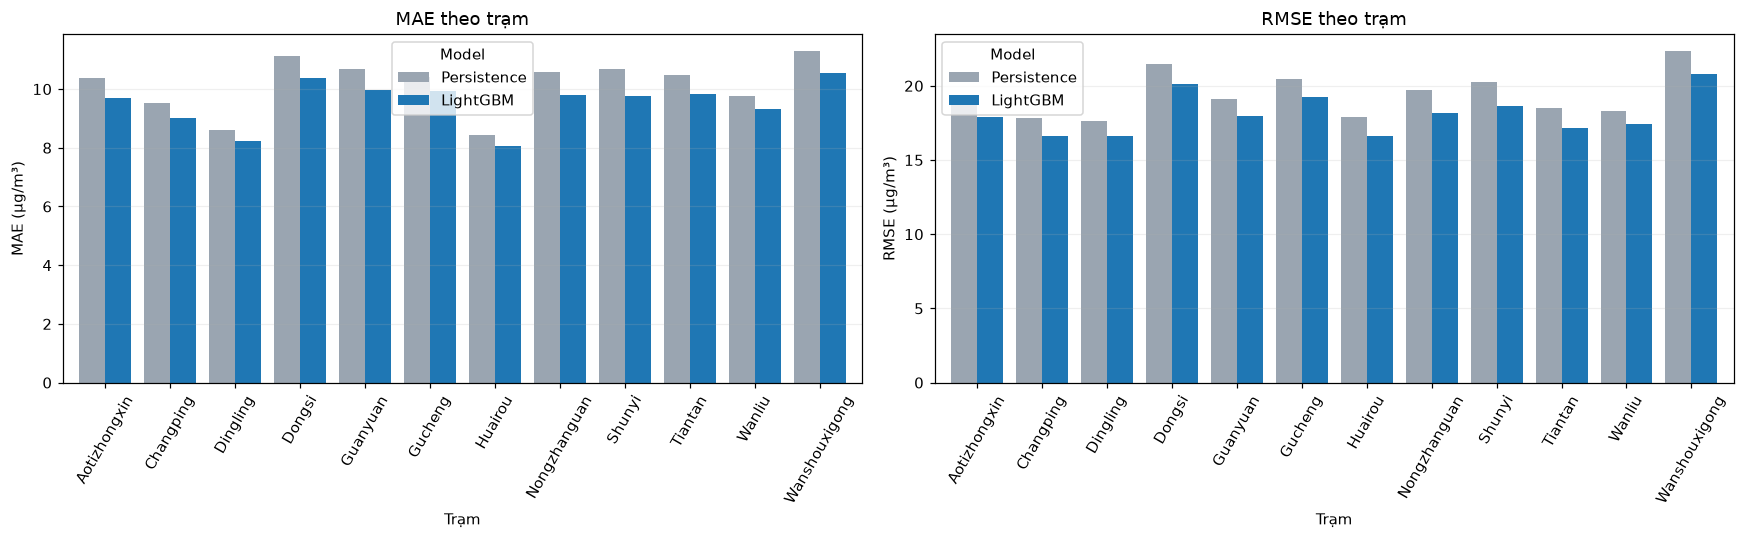

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, metric in zip(axes, ["MAE", "RMSE"]):
    table = station_results.pivot(index="station_id", columns="Model", values=metric)
    table.index = table.index.str.replace("beijing_", "", regex=False)
    table[model_names].plot.bar(ax=ax, color=["#9aa5b1", "#1f77b4"], width=0.8)
    ax.set_title(f"{metric} theo trạm")
    ax.set_xlabel("Trạm")
    ax.set_ylabel(f"{metric} (µg/m³)")
    ax.tick_params(axis="x", rotation=60)
    ax.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

## 10. Sai số theo tháng 



In [34]:
monthly_rows = []
for month, frame in predictions.groupby("target_month"):
    for name in model_names:
        monthly_rows.append({"Month": month, **metric_row(frame, name)})

monthly_results = pd.DataFrame(monthly_rows)
assert monthly_results["Month"].unique().tolist() == expected_months
assert len(monthly_results) == 24
display(monthly_results.round(3))

,Month,Model,MAE,RMSE,So_mau
0,2016-03,Persistence,9.796,17.847,8610
1,2016-03,LightGBM,9.137,16.337,8610
2,2016-04,Persistence,10.243,17.716,8206
3,2016-04,LightGBM,9.507,15.997,8206
4,2016-05,Persistence,9.390,16.871,8614
5,2016-05,LightGBM,9.237,17.831,8614
6,2016-06,Persistence,8.564,13.315,8375
7,2016-06,LightGBM,8.152,12.509,8375
8,2016-07,Persistence,8.745,14.414,8541
9,2016-07,LightGBM,8.112,13.116,8541


### Biểu đồ cột

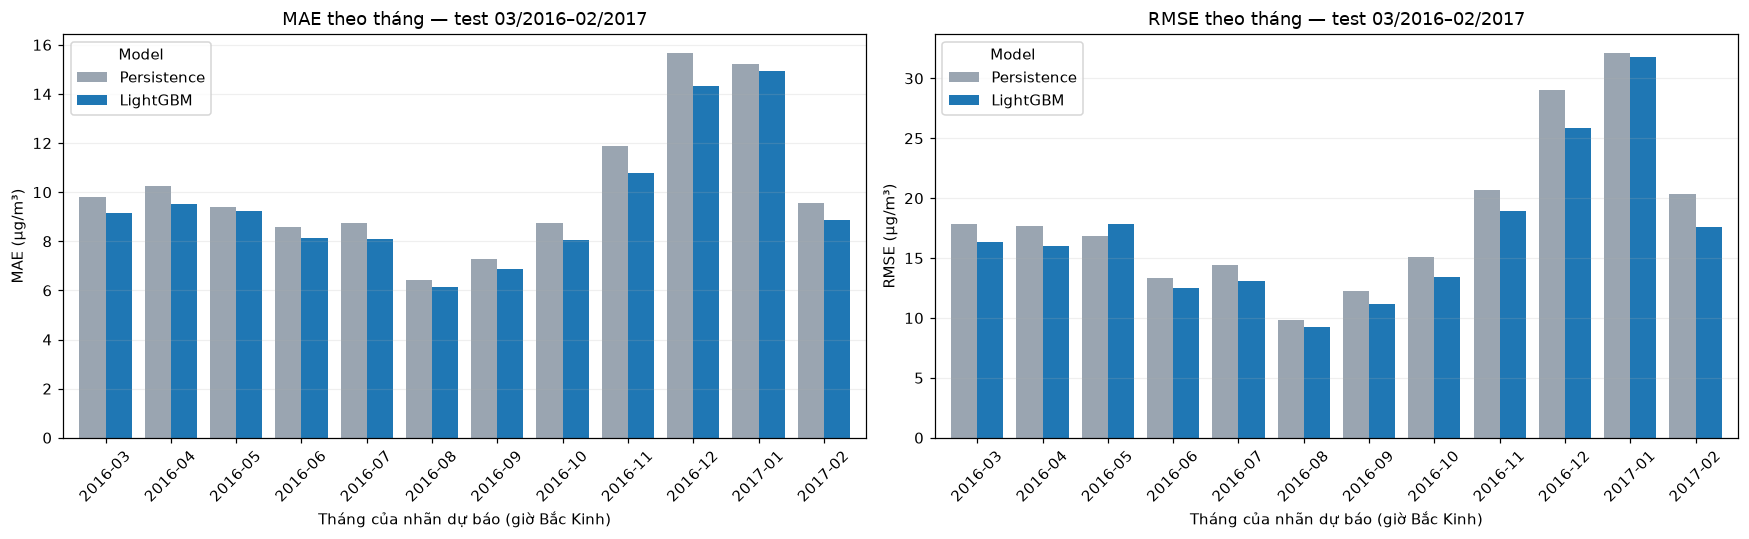

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, metric in zip(axes, ["MAE", "RMSE"]):
    table = monthly_results.pivot(index="Month", columns="Model", values=metric)
    table[model_names].plot.bar(ax=ax, color=["#9aa5b1", "#1f77b4"], width=0.8)
    ax.set_title(f"{metric} theo tháng — test 03/2016–02/2017")
    ax.set_xlabel("Tháng của nhãn dự báo (giờ Bắc Kinh)")
    ax.set_ylabel(f"{metric} (µg/m³)")
    ax.tick_params(axis="x", rotation=45)
    ax.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

## 11. Độ quan trọng của đặc trưng



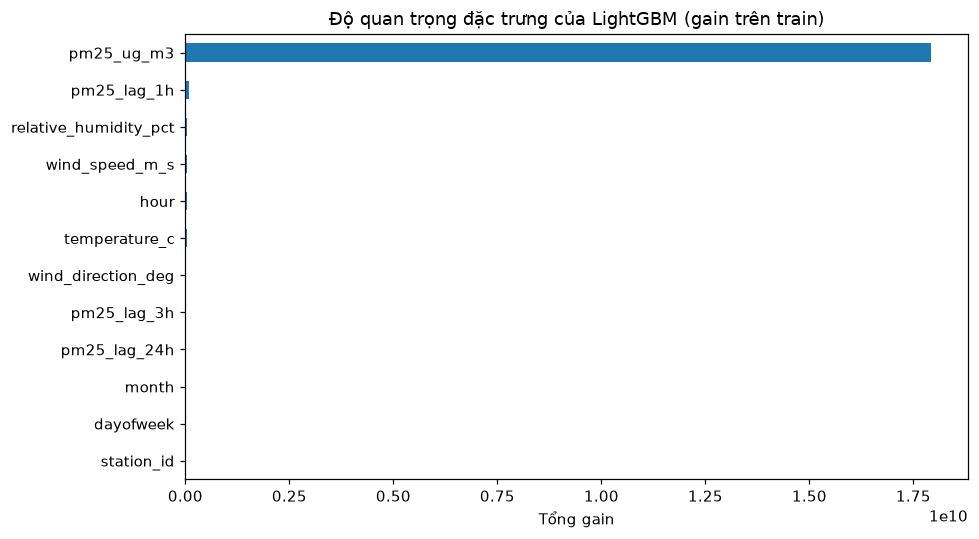

In [37]:
importance = pd.Series(
    model.booster_.feature_importance(importance_type="gain"),
    index=features,
).sort_values()

importance.plot.barh(figsize=(9, 5), color="#1f77b4")
plt.title("Độ quan trọng đặc trưng của LightGBM (gain trên train)")
plt.xlabel("Tổng gain")
plt.tight_layout()
plt.show()

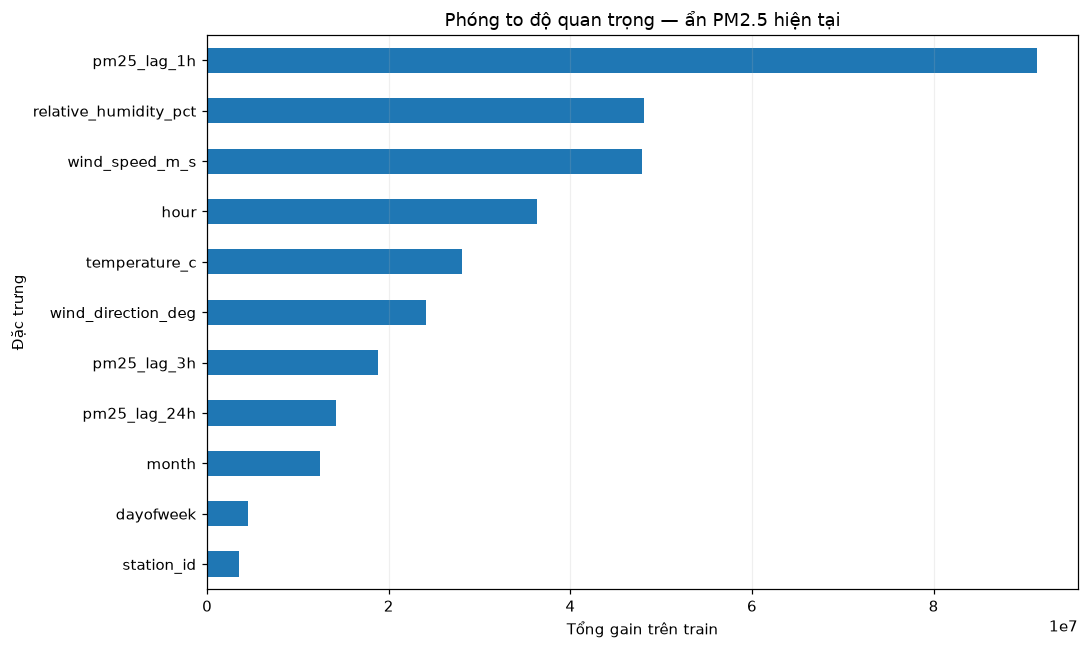

In [38]:
importance_zoom = importance.drop("pm25_ug_m3").sort_values()

importance_zoom.plot.barh(figsize=(10, 6), color="#1f77b4")
plt.title("Phóng to độ quan trọng — ẩn PM2.5 hiện tại")
plt.xlabel("Tổng gain trên train")
plt.ylabel("Đặc trưng")
plt.grid(axis="x", alpha=0.2)
plt.tight_layout()
plt.show()